# Classify snow-covered area (SCA) in Sentinel-2, Landsat 8/9, and PlanetScope imagery: full pipelines

Rainey Aberle

Department of Geosciences, Boise State University

2022

### Requirements:
- Area of Interest (AOI) shapefile: used to query and crop imagery 
- Google Earth Engine (GEE) account: used to query imagery and the DEM (if no DEM is provided). Sign up for a free account [here](https://earthengine.google.com/new_signup/). 
- Digital elevation model (DEM; _optional_): used to extract elevations over the AOI and for each snowline. If no DEM is provided, the ArcticDEM Mosaic will be used where there is coverage; otherwise, the NASADEM will be used.
- Pre-downloaded PlanetScope 4-band Surface Reflectance images (_optional_): download using the `Planet_images_order_download.ipynb` or through Planet Explorer. 

### Outline:
__0. Setup__ paths in directory, file locations, authenticate GEE - _modify this section!_

__1. Sentinel-2 Top of Atmosphere (TOA) imagery:__ full pipeline

__2. Sentinel-2 Surface Reflectance (SR) imagery:__ full pipeline

__3. Landsat 8/9 Surface Reflectance (SR) imagery:__ full pipeline

__4. PlanetScope Surface Reflectance (SR) imagery:__ full pipeline

-------


### 0. Setup

#### Define paths in directory and desired settings. 
Modify lines located within the following:

`#### MODIFY HERE ####`  

`#####################`

In [28]:
##### MODIFY HERE #####

# -----Paths in directory
# Name of study site used for output file names
site_name = 'Panmah_Glacier'
# path to folder containing AOI file
aoi_path = '/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/' + site_name + '/AOIs/'
# AOI file name
aoi_fn = site_name + '_outline.shp' 
# path to folder containing dem raster file
dem_path = '/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/' + site_name + '/DEMs/'
# DEM file name
# Note: set dem_fn=None if you want to use the ArcticDEM or NASADEM via Google Earth Engine
dem_fn = None
# path for outputs
out_path = aoi_path + '/test_cloud_filter/'
# path to PlanetScope images
# Note: set ps_im_path=None if not using PlanetScope
ps_im_path = None #out_path + 'PlanetScope/raw_images/'

# -----Define image search settings
# Google Earth Engine project ID (default = "ee-{YOUR USER NAME}")
project_id = 'ee-silastwickler'
# date ranges (inclusive)
date_start = '2019-06-01'
date_end = '2019-06-30'
month_start = 6
month_end = 10
# whether to mask clouds in images
mask_clouds = True
# minimum portion of AOI covered after cloud filtering
min_aoi_coverage = 70

# -----Determine image download, clipping & plotting settings
# Note: if im_download = False, but images over the aoi exceed GEE limit, images must be downloaded regardless.
im_download = False  # = True to download all satellite images by default
delineate_snowline = False # = True to delineate the snowline in classified images
plot_results = True # = True to plot figures of results for each image where applicable
verbose = True # = True to print details for each image during each step
skip_clipped = False # = True to skip PlanetScope images where bands appear "clipped", i.e. max(blue) < 0.8

#######################

# -----Import packages
import xarray as xr
import os
import glob
import numpy as np
from matplotlib import pyplot as plt
import geopandas as gpd
import sys
import ee
import json
from tqdm.auto import tqdm
from joblib import load
from shapely.geometry import MultiPolygon, Polygon
import warnings
warnings.filterwarnings('ignore')

# -----Make output directory if it doesn't exist
if not os.path.exists(out_path):
    os.mkdir(out_path)
    print('Made directory for outputs: ', out_path)

# -----Set paths for output files
s2_toa_im_path = os.path.join(out_path, 'Sentinel-2_TOA')
s2_sr_im_path = os.path.join(out_path, 'Sentinel-2_SR')
l_im_path = os.path.join(out_path, 'Landsat')
ps_im_masked_path = os.path.join(out_path, 'PlanetScope', 'masked')
ps_im_mosaics_path = os.path.join(out_path, 'PlanetScope', 'mosaics')
im_classified_path = os.path.join(out_path, 'classified')
snow_cover_stats_path = os.path.join(out_path, 'snow_cover_stats')
figures_out_path = os.path.join(out_path, 'figures')

# -----Import pipeline utilities
# When running locally, must import from "functions" folder
script_path = os.getcwd()
if "functions" in os.listdir(os.path.join(script_path, '..')):
    sys.path.append(os.path.join(script_path, '..', 'functions'))
# In Docker image, all files are in "/app" folder
else:
    sys.path.append(os.path.join(script_path))
import pipeline_utils as utils
import PlanetScope_preprocessing as psp
import importlib

importlib.reload(utils)

# -----Load dataset dictionary
dataset_dict_fn = os.path.join(script_path, '..', 'inputs-outputs', 'datasets_characteristics.json')
dataset_dict = json.load(open(dataset_dict_fn))

#### Authenticate and initialize Google Earth Engine (GEE). 

__Note:__ The first time you run the following cell, you will be asked to authenticate your GEE account for use in this notebook. This will send you to an external web page, where you will walk through the GEE authentication workflow and copy an authentication code back into the space below this cell when prompted. 

In [17]:
try:
    ee.Initialize(project=project_id)
except: 
    ee.Authenticate()
    ee.Initialize(project=project_id)

#### Load AOI and DEM

Optimal UTM CRS = EPSG:32643
Clipped NASADEM already exists in directory, loading...


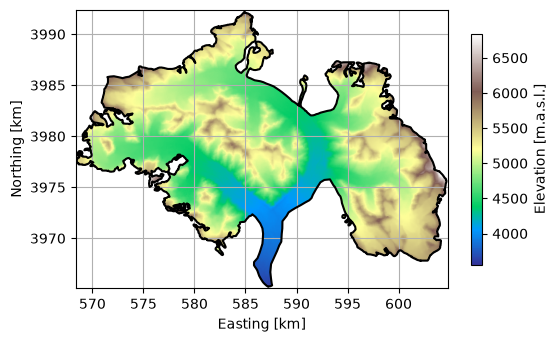

In [3]:
# -----Load AOI as gpd.GeoDataFrame
aoi = gpd.read_file(os.path.join(aoi_path, aoi_fn))
# reproject the AOI to WGS84 to solve for the optimal utm zone
aoi_wgs = aoi.to_crs('EPSG:4326')
aoi_wgs_centroid = [aoi_wgs.geometry[0].centroid.xy[0][0],
                    aoi_wgs.geometry[0].centroid.xy[1][0]]
# grab the optimal UTM zone EPSG code
epsg_utm = utils.convert_wgs_to_utm(aoi_wgs_centroid[0], aoi_wgs_centroid[1])
print('Optimal UTM CRS = EPSG:' + str(epsg_utm))
# reproject AOI to the optimal UTM zone
aoi_utm = aoi.to_crs(f'EPSG:{epsg_utm}')

# -----Load DEM as Xarray DataSet
if dem_fn is None:
    # query GEE for DEM
    dem = utils.query_gee_for_dem(aoi_utm, site_name, dem_path)
else:
    # load DEM as xarray DataSet
    dem = xr.open_dataset(os.path.join(dem_path, dem_fn))
    dem_crs = str(dem.rio.crs.to_epsg())
    dem = utils.adjust_dem_data_vars(dem)
    # set no data values to NaN
    dem = xr.where((dem > 1e38) | (dem <= -9999), np.nan, dem)
    # reproject the DEM to the optimal utm zone
    dem = dem.rio.write_crs(f'EPSG:{dem_crs}')
    if dem_crs is not epsg_utm:
        dem = dem.rio.reproject(f'EPSG:{epsg_utm}')

# -----Plot
fig, ax = plt.subplots(1, 1, figsize=(6,6))
dem_im = ax.imshow(dem.elevation.data, cmap='terrain', 
          extent=(np.min(dem.x.data)/1e3, np.max(dem.x.data)/1e3, np.min(dem.y.data)/1e3, np.max(dem.y.data)/1e3))
if type(aoi_utm.geometry[0])==Polygon:
    ax.plot([x/1e3 for x in aoi_utm.geometry[0].exterior.coords.xy[0]],
            [y/1e3 for y in aoi_utm.geometry[0].exterior.coords.xy[1]], '-k')
elif type(aoi_utm.geometry[0])==MultiPolygon:
    [ax.plot([x/1e3 for x in geom.exterior.coords.xy[0]],
            [y/1e3 for y in geom.exterior.coords.xy[1]], '-k') for geom in aoi_utm.geometry[0].geoms]
ax.grid()
ax.set_xlabel('Easting [km]')
ax.set_ylabel('Northing [km]')
fig.colorbar(dem_im, ax=ax, shrink=0.5, label='Elevation [m.a.s.l.]')
plt.show()

## 1. Sentinel-2 TOA imagery

In [8]:
# -----Query GEE for imagery and run classification pipeline
# Define dataset
dataset = 'Sentinel-2_TOA'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_TOA_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_TOA_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
run_pipeline=True
utils.query_gee_for_imagery_yearly(aoi_utm, dataset, date_start, date_end, month_start, month_end, mask_clouds, min_aoi_coverage,
                                im_download, s2_toa_im_path, run_pipeline, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, dem, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)

Task was destroyed but it is pending!
task: <Task pending name='Task-75' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-76' coro=<Kernel.shell_main() running at /Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:564]>
Task was destroyed but it is pending!
task: <Task pending name='Task-76' coro=<Kernel.shell_main() running at /Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


 
2019-07-05 2019-07-08
Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-07-05', '2019-07-08')
number of dates in subsetted image collection 1


  0%|          | 0/1 [00:00<?, ?it/s]

...

20190707_Sentinel-2_TOA.tif: |  | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Classified image saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs/classified/20190707_Panmah_Glacier_Sentinel-2_TOA_classified.nc
Snowline saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs/snow_cover_stats/20190707_Panmah_Glacier_Sentinel-2_TOA_snow_cover_stats.csv


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.057600000000000005..1.2015].


Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs/figures/20190707_Panmah_Glacier_Sentinel2_TOA_snow_cover.png
Done!


[]

## 2. Sentinel-2 SR imagery

In [29]:
# -----Query GEE for imagery and run classification pipeline
# Define dataset
dataset = 'Sentinel-2_SR'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_SR_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_SR_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
run_pipeline=True
utils.query_gee_for_imagery_yearly(aoi_utm, dataset, date_start, date_end, month_start, month_end, mask_clouds, min_aoi_coverage,
                                im_download, s2_sr_im_path, run_pipeline, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, dem, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)

 
2019-06-01 2019-06-30
Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-30')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 3


  0%|          | 0/3 [00:00<?, ?it/s]

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190612_Sentinel-2_SR.tif download size (raw: 1.16 GB).


...

20190627_Sentinel-2_SR.tif: |   | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Classified image saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/classified/20190627_Panmah_Glacier_Sentinel-2_SR_classified.nc
Snowline saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/snow_cover_stats/20190627_Panmah_Glacier_Sentinel-2_SR_snow_cover_stats.csv


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0001..1.5873000000000002].


Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/figures/20190627_Panmah_Glacier_Sentinel2_SR_snow_cover.png
Done!


[]

## 3. Landsat 8/9 SR imagery

In [25]:
# -----Query GEE for imagery (and download to l_im_path if necessary)
# Define dataset
dataset = 'Landsat'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Landsat_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Landsat_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
run_pipeline=True
im_download=True
#start_date = '2019-06-01'
#end_date = '2019-07-30'
utils.query_gee_for_imagery_yearly(aoi_utm, dataset, date_start, date_end, month_start, month_end, mask_clouds, min_aoi_coverage,
                                im_download, l_im_path, run_pipeline, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, dem, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)

 
2019-06-01 2019-06-30
Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-30')
number of dates in subsetted image collection 4


  0%|          | 0/4 [00:00<?, ?it/s]

20190604_Landsat.tif: |         | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

...

Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/figures/20190620_Panmah_Glacier_Landsat_snow_cover.png


20190629_Landsat.tif: |         | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.1954075..1.3380475].


Classified image saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/classified/20190629_Panmah_Glacier_Landsat_classified.nc
Snowline saved to file: /Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/snow_cover_stats/20190629_Panmah_Glacier_Landsat_snow_cover_stats.csv
Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/figures/20190629_Panmah_Glacier_Landsat_snow_cover.png
Done!


[]

## 4. PlanetScope SR imagery

### Pre-process raw imagery

In [7]:
# -----Read surface reflectance image file names
os.chdir(ps_im_path)
im_fns = sorted(glob.glob('*SR*.tif'))

# ----Mask clouds and cloud shadows in all images
plot_results = False
if mask_clouds:
    print('Masking images using cloud bitmask...')
    for im_fn in tqdm(im_fns):
        psp.planetscope_mask_image_pixels(ps_im_path, im_fn, ps_im_masked_path, save_outputs=True, plot_results=plot_results)
# read masked image file names
os.chdir(ps_im_masked_path)
im_masked_fns = sorted(glob.glob('*_mask.tif'))

# -----Mosaic images captured within same hour
print('Mosaicking images captured in the same hour...')
if mask_clouds:
    psp.planetscope_mosaic_images_by_date(ps_im_masked_path, im_masked_fns, ps_im_mosaics_path, aoi_utm)
    print(' ')
else:
    psp.planetscope_mosaic_images_by_date(ps_im_path, im_fns, ps_im_mosaics_path, aoi_utm)
    print(' ')

TypeError: chdir: path should be string, bytes, os.PathLike or integer, not NoneType

### Run snow detection workflow

In [ ]:
# -----Load trained classifier and feature columns
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'PlanetScope_classifier_all_sites.joblib')
clf = load(clf_fn)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'PlanetScope_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
dataset = 'PlanetScope'

# -----Iterate over image mosaics
# read image mosaic file names
os.chdir(ps_im_mosaics_path)
im_mosaic_fns = sorted(glob.glob('*.tif'))
# create polygon(s) of the top and bottom 20th percentile elevations within the AOI
polygons_top, polygons_bottom = psp.create_aoi_elev_polys(aoi_utm, dem)
# loop through images
for im_mosaic_fn in tqdm(im_mosaic_fns):

    # -----Determine image date from image mosaic file name
    im_date = im_mosaic_fn[0:4] + '-' + im_mosaic_fn[4:6] + '-' + im_mosaic_fn[6:8] + 'T' + im_mosaic_fn[9:11] + ':00:00'
    im_dt = np.datetime64(im_date)
    if verbose:
        print(im_date)

    # -----Open image mosaic
    im_da = xr.open_dataset(os.path.join(ps_im_mosaics_path, im_mosaic_fn))

    # -----Adjust radiometry
    im_adj, im_adj_method = psp.planetscope_adjust_image_radiometry(im_da, im_dt, polygons_top, polygons_bottom,
                                                                    dataset_dict, skip_clipped)
    if type(im_adj) is str:  # skip if there was an error in adjustment
        continue    
    
    # -----Check if classified image already exists in file
    # check if classified image already exists in file
    im_classified_fn = im_date.replace('-', '').replace(':',
                                                        '') + '_' + site_name + '_' + dataset + '_classified.nc'
    if os.path.exists(os.path.join(im_classified_path, im_classified_fn)):
        if verbose:
            print('Classified image already exists in file, loading...')
        im_classified = xr.open_dataset(os.path.join(im_classified_path, im_classified_fn))
        
        # remove no data values
        im_classified = xr.where(im_classified == -9999, np.nan, im_classified)
        # reproject to UTM
        im_classified = im_classified.rio.write_crs('EPSG:4326')
        im_classified = im_classified.rio.reproject('EPSG:' + epsg_utm)
    else:

        # -----Check that image mosaic covers at least min_aoi_coverage of the AOI
        # Create dummy band for AOI masking comparison
        im_adj['aoi_mask'] = (['time', 'y', 'x'], np.ones(np.shape(im_adj[dataset_dict[dataset]['RGB_bands'][0]].data)))
        im_aoi = im_adj.rio.clip(aoi_utm.geometry, im_adj.rio.crs)
        # Calculate the percentage of real values in the AOI    
        perc_real_values_aoi = (len(np.where(~np.isnan(np.ravel(im_aoi[dataset_dict[dataset]['RGB_bands'][0]].data)))[0])
                                / len(np.where(~np.isnan(np.ravel(im_aoi['aoi_mask'].data)))[0]))
        if perc_real_values_aoi < min_aoi_coverage:
            if verbose:
                print(f'Less than {min_aoi_coverage}% coverage of the AOI, skipping image...')
                print(' ')
            continue

        # -----Classify image
        im_classified = utils.classify_image(im_adj, clf, feature_cols, aoi_utm, dataset_dict,
                                         dataset, im_classified_fn, im_classified_path, verbose)
        if type(im_classified) == str:
            continue

    # -----Calculate snow cover stats
    # Check if snow cover stats already exists in file
    snow_cover_stats_fn = (im_date.replace('-', '').replace(':', '') + '_' + site_name + '_' + dataset
                            + '_snow_cover_stats.csv')
    if os.path.exists(os.path.join(snow_cover_stats_path, snow_cover_stats_fn)):
        # No need to load snow cover stats if it already exists
        continue
    else:
        # Calculate snow cover stats
        scs_df = utils.calculate_snow_cover_stats(dataset_dict, dataset, im_date, im_adj, im_classified, dem, aoi_utm, 
                                                    site_name, delineate_snowline, snow_cover_stats_fn, snow_cover_stats_path, 
                                                    figures_out_path, plot_results, verbose)
        plt.close()
    if verbose:
        print(' ')